<center><h1> Sathiya_Rohith_HW6 </h1></center>

Name: Rohith Sathiya
<br>Github Username: Rohith-s9401
<br>USC ID: 7480930295

### (a) Download the APS Failure data

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sb
import sklearn.metrics as metrics
import seaborn as sns

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as imbpipeline
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_curve, auc, f1_score, accuracy_score, roc_auc_score
from sklearn.model_selection import KFold, cross_val_score,GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost.sklearn import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
file_train = 'Data/aps_failure_training_set.csv'
file_test = 'Data/aps_failure_test_set.csv'

df_train = pd.read_csv(file_train, skiprows=20, na_values = 'na')
df_test = pd.read_csv(file_test, skiprows=20, na_values = 'na')
df_train = df_train.replace({'neg': 0, 'pos': 1, 'na':np.nan})
df_test = df_test.replace({'neg': 0, 'pos': 1, 'na':np.nan})
print("Training Data: ", df_train.shape)
print("Testing Data: ", df_test.shape)

Training Data:  (60000, 171)
Testing Data:  (16000, 171)


In [3]:
df_train_X = df_train.iloc[:, 1:]
df_train_Y = df_train.iloc[:, 0]
df_test_X = df_test.iloc[:, 1:]
df_test_Y = df_test.iloc[:, 0]

In [4]:
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df_train_X_imputed = pd.DataFrame(imputer.fit_transform(df_train_X), columns = df_train.columns[1:])
df_test_X_imputed = pd.DataFrame(imputer.fit_transform(df_test_X), columns = df_test.columns[1:])

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

#### Some examples of different data Imputation Techniques:
1. Imputation using statistics like mean or median but can only be done with numeric values, as these measures are meant solely for numeric data. We replace the missing values with the corresponding means or medians.
2. Imputation using KNN with imputers of sklearn like KNNImputer in which we assign a value to the missing value by checking the feature similarity and predict new data points.
3. Imputation using multivariate imputation by chained equation (MICE). In this technique, we fill the missing values multiple times and then pooling them together to get a single result.
4. We can use the most frequent value or a constant value can be done (Can be done irrespective of data type). We calculate the most frequent element in a column and use that to fill in all the missing values in the column. We can also use some constant of the same data type to fill in missing values like zero.


<b> I used imputations with the mean of the data, as I had earlier cleaned and converted each value into numeric values.</b>

#### (ii) Calculate the coefficient of variation

In [5]:
cv_results = {} 
for col in df_train_X_imputed.columns:
    mu = df_train_X_imputed[col].mean()
    sigma = df_train_X_imputed[col].std()
    cv_results[col] = [mu, sigma, sigma/mu]
coefficient_of_variation = pd.DataFrame(cv_results)
coefficient_of_variation.index = ['mu', 'std', 'cv']
coefficient_of_variation

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
mu,59336.499567,0.713189,3.560143e+08,1.906206e+05,6.819130,11.006817,221.636367,975.722261,8606.014529,88591.281094,...,4.454897e+05,211126.447302,4.457343e+05,3.939462e+05,3.330582e+05,3.462714e+05,138729.983179,8388.914629,0.090579,0.212756
std,145430.056532,1.660588,7.724678e+08,3.504515e+07,158.142022,205.375337,20363.631242,34008.750683,149479.100501,757459.796689,...,1.149060e+06,540272.166338,1.161763e+06,1.114758e+06,1.063164e+06,1.718366e+06,446989.425928,47204.242869,4.268529,8.627929
cv,2.450938,2.328400,2.169767e+00,1.838476e+02,23.190937,18.658921,91.878565,34.854950,17.369143,8.550049,...,2.579319e+00,2.558998,2.606402e+00,2.829722e+00,3.192128e+00,4.962483e+00,3.222010,5.626979,47.124953,40.553250


#### (iii) Plot a correlation matrix

In [6]:
correlation = df_train_X_imputed.corr()
correlation.style.background_gradient(cmap = 'coolwarm')

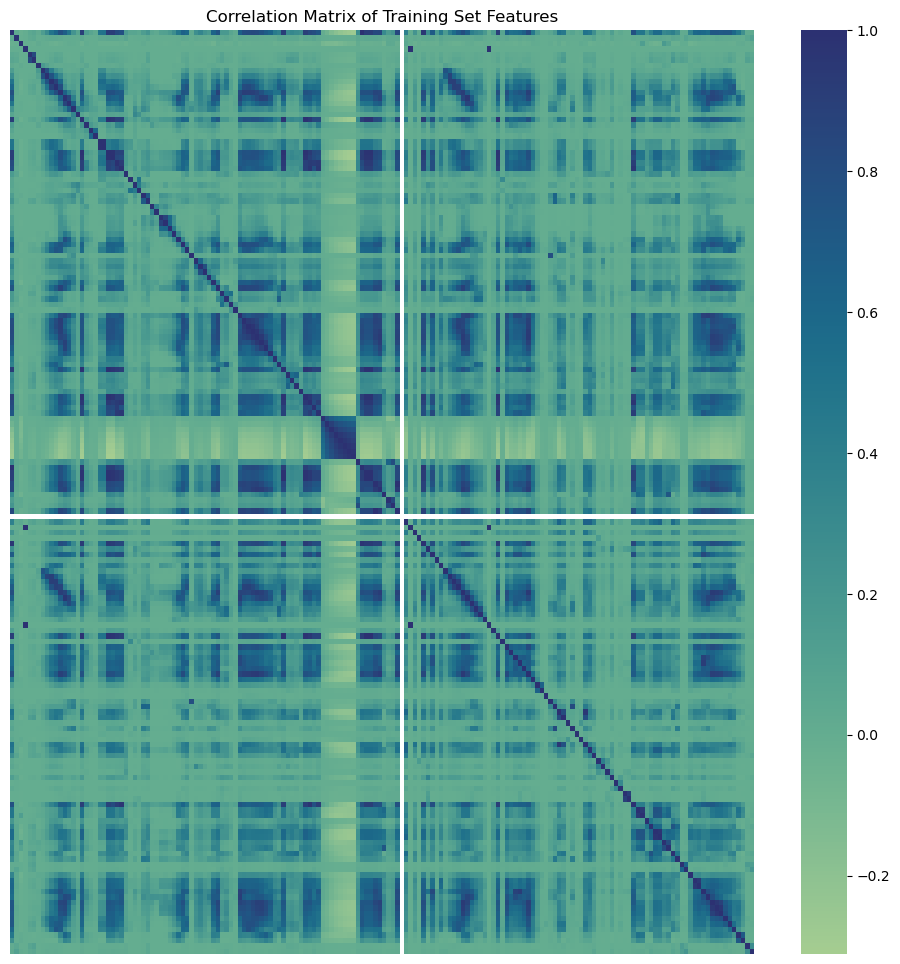

In [7]:
fit, axes = plt.subplots(figsize=(12, 12))
sb.heatmap(df_train_X_imputed.corr(), cmap = "crest", xticklabels=False, yticklabels=False, ax=axes)
plt.title("Correlation Matrix of Training Set Features")
plt.show()

#### (iv) Make scatter plots and box plots

In [8]:
sorted_index = np.argsort(coefficient_of_variation.iloc[2])[::-1][:math.floor(math.sqrt(170))]
selected_columns = df_train_X_imputed.columns[sorted_index]
print('Selected features:')
coefficient_of_variation[selected_columns][2:].T

Selected features:


,cv
cs_009,235.277605
cf_000,184.233092
co_000,183.949017
ad_000,183.847620
dh_000,114.984991
dj_000,109.647285
ag_000,91.878565
as_000,86.416904
ay_009,83.786063
az_009,76.967978


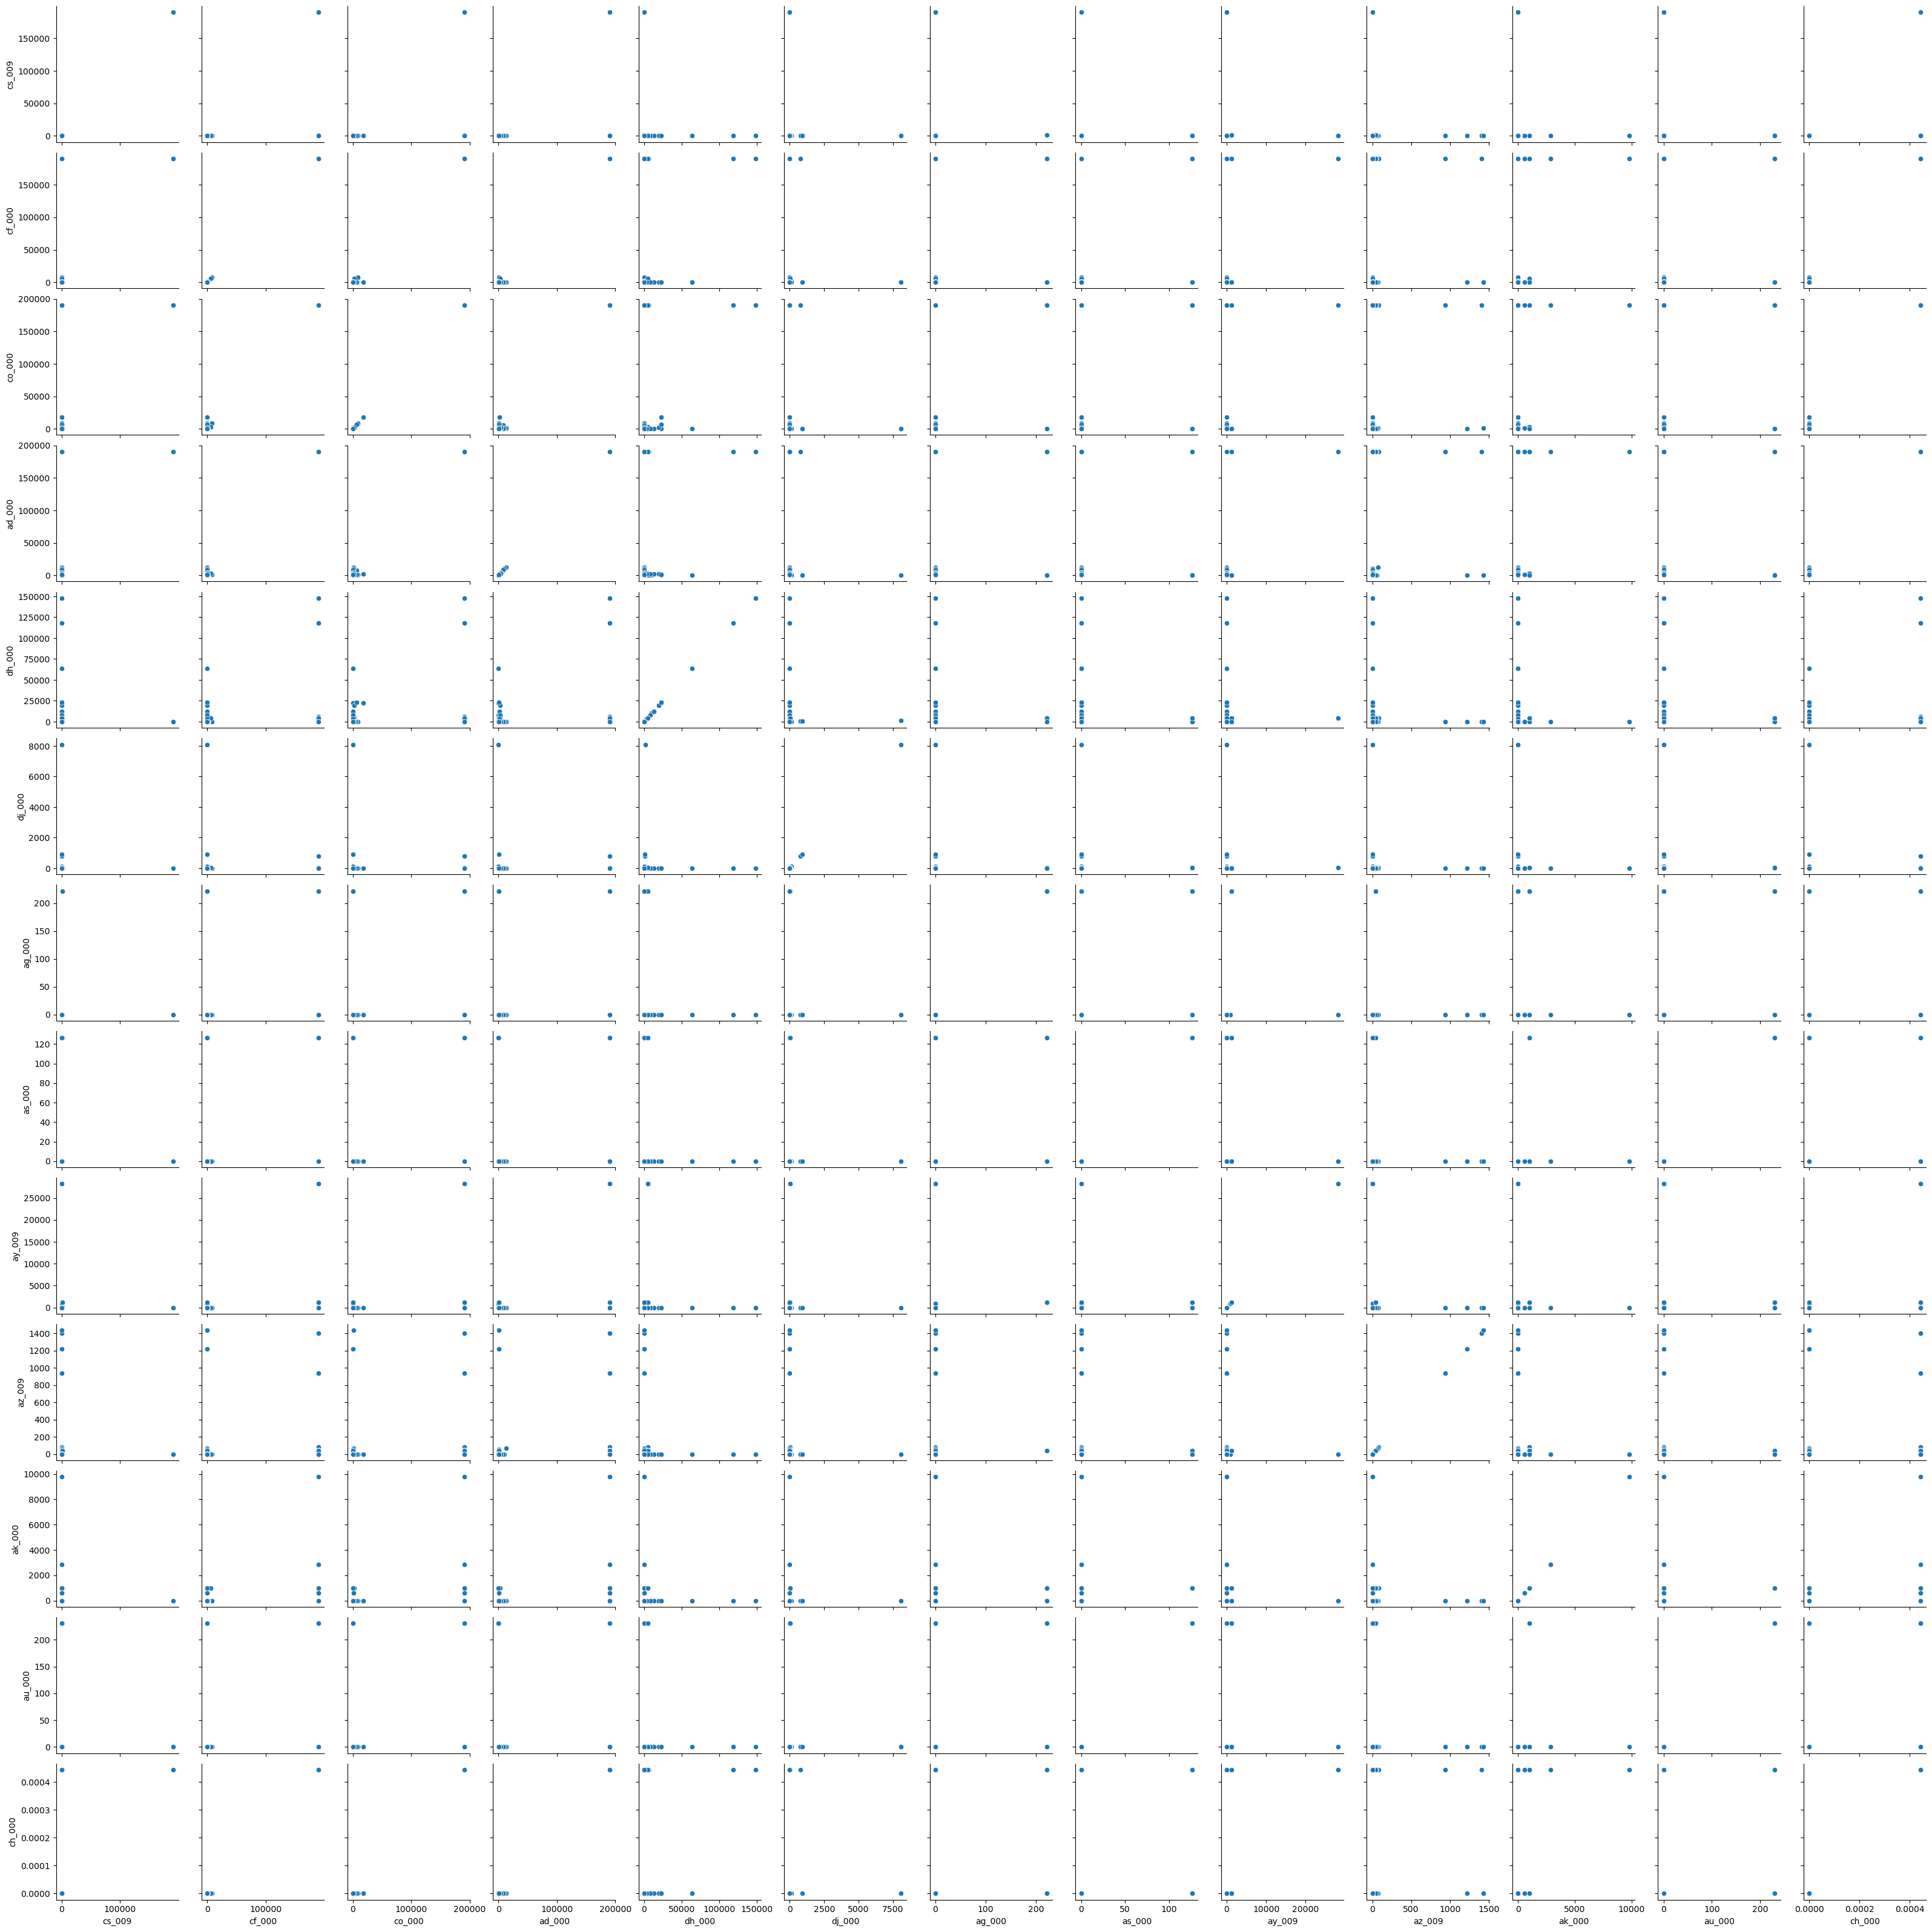

In [9]:
sns.pairplot(data = df_train_X_imputed[selected_columns].sample(1000), diag_kind = None)

[None]

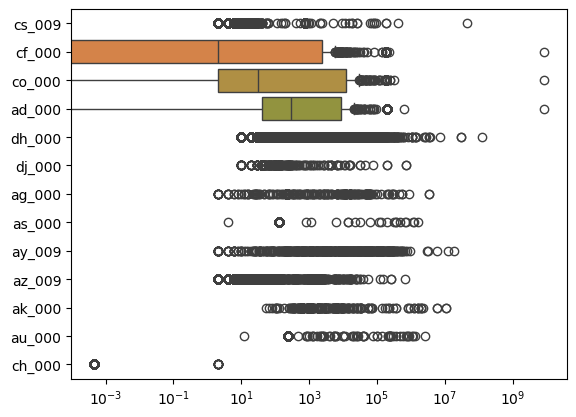

In [10]:
box = sns.boxplot(data = df_train_X_imputed[selected_columns], orient = 'h')
box.set(xscale = "log")

Conclusion:<br>
* From the scatterplots only we can't draw any conclusions.
* Since mean is used as the imputation strategy, any outlier can easily affect the datapoints.

#### (v) Is this data set imbalanced?

In [11]:
negative_values = df_train_Y.value_counts()[0]
positive_values = df_train_Y.value_counts()[1]

print("Total positive values in training sets are: ", positive_values)
print("Total negative values in training sets are: ", negative_values)

Total positive values in training sets are:  1000
Total negative values in training sets are:  59000


Conclusion:<br>
From the above values, we can clearly see that the number of positive samples are very less compared to the samples that have negative classes.<br>
By looking at the train/test data, we can see that the percetage of positive class is just $\frac{1000}{60000} = 1.667%$. Hence the data is <b>highly imbalanced</b>.

In [12]:
def plot_roc_curve(y_train, y_train_prob, title):
    fig, axes = plt.subplots(figsize = (6, 4))
    axes.set_title(f"ROC curves for {title}")
    y_predicted = y_train_prob[:, 1]
    fpr, tpr, thresholds = roc_curve(y_train, y_predicted)
    roc_auc = auc(fpr, tpr)
    axes.plot(fpr, tpr, label = f"ROC Curve Area: {round(roc_auc, 5)}")
    axes.plot([0, 1], [0, 1], "--")
    axes.set_xlabel("False Positive Rate")
    axes.set_ylabel("True Positive Rate")
    axes.legend()
    plt.show()

In [13]:
def model_summary(y_train, y_train_predicted, y_train_prob,
                  title, is_xgboost=False):

    conf_matrix = confusion_matrix(y_train, y_train_predicted)
    print(f'Confusion Matrix: \n{conf_matrix}\n')

    accuracy = round(accuracy_score(y_train, y_train_predicted), 5)
    print(f'Accuracy Score: {accuracy}')
    print(f'Error: {round(1 - accuracy, 5)}')

    if is_xgboost:
        roc = round(roc_auc_score(y_train, y_train_prob[:, 1]), 5)
        print(f'ROC AUC Score: {roc}')

    plot_roc_curve(y_train, y_train_prob, title)

    data = {
        'conf_matrix': conf_matrix,
        'accuracy': accuracy,
        'error': round(1 - accuracy, 5)
    }

    if is_xgboost:
        data['roc'] = roc

    return data

In [14]:
def fit_rf(x_train, y_train, is_balanced = False):
    if not is_balanced:
        model = RandomForestClassifier(max_depth = 5, random_state = 60000, oob_score = True)
    else:
        model = RandomForestClassifier(max_depth = 5, random_state = 60000, 
                                          class_weight = 'balanced', oob_score = True)
    model.fit(x_train, y_train)
    return model

Confusion Matrix: 
[[58972    28]
 [  450   550]]

Accuracy Score: 0.99203
Error: 0.00797


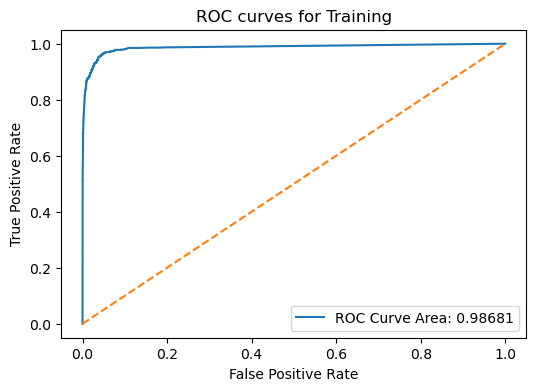

In [15]:
y_train = df_train_Y
model = fit_rf(df_train_X_imputed, y_train)
y_train_predicted = model.predict(df_train_X_imputed)
y_train_prob = model.predict_proba(df_train_X_imputed)
_ = model_summary(y_train, y_train_predicted, y_train_prob, "Training")

Confusion Matrix: 
[[15612    13]
 [  180   195]]

Accuracy Score: 0.98794
Error: 0.01206


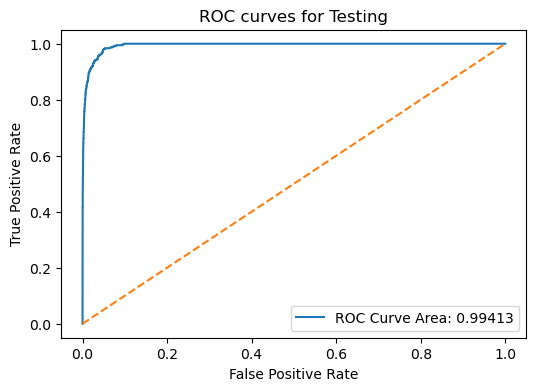

In [16]:
y_test = df_test_Y
y_test_predicted = model.predict(df_test_X_imputed)
y_test_prob = model.predict_proba(df_test_X_imputed)
_ = model_summary(y_test, y_test_predicted, y_test_prob, "Testing")

In [17]:
train_oob_error = round(1 - model.oob_score_, 5)
test_error = round(1 - accuracy_score(y_test, y_test_predicted), 5)
print("Train OOB Error: {}".format(train_oob_error))
print("Testing Error: {}".format(test_error))

Train OOB Error: 0.00937
Testing Error: 0.01206


### Comparison:
* Test error is 28.71% more than the Train OOB error
* Due to less positive data points, model majorly learns negative class and so false negatives are higher in the test confusion matrix resulting in higher overall testing error compared to training error.

### (d) Research class imbalance in random forest

### Hypothesis: 

There are two ways to handle class imbalance: 

1. **RandomForestClassifier with class_weight = 'balanced:** Weights associated with classes in the form {class_label: weight}. If not given, all classes are supposed to have weight one. For multi-output problems, a list of dicts can be provided in the same order as the columns of y.
2. **BalancedRandomForestClassifier:** A balanced random forest classifier. This model randomly undersamples each boostrap sample to negate imbalance effect.

Confusion Matrix: 
[[56563  2437]
 [   31   969]]

Accuracy Score: 0.95887
Error: 0.04113


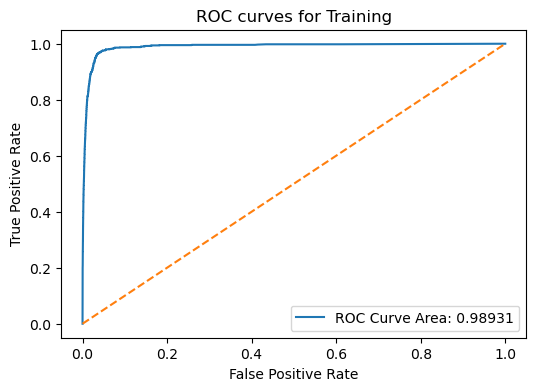

In [18]:
model = fit_rf(df_train_X_imputed, y_train, is_balanced = True)
y_train_predicted = model.predict(df_train_X_imputed)
y_train_prob = model.predict_proba(df_train_X_imputed)
_ = model_summary(y_train, y_train_predicted, y_train_prob, "Training")

Confusion Matrix: 
[[14992   633]
 [   15   360]]

Accuracy Score: 0.9595
Error: 0.0405


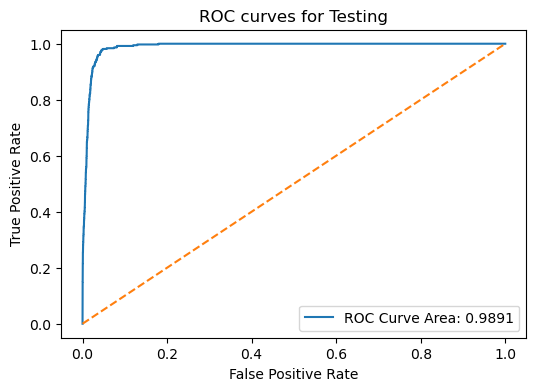

In [19]:
y_test_predicted = model.predict(df_test_X_imputed)
y_test_prob = model.predict_proba(df_test_X_imputed)
_ = model_summary(y_test, y_test_predicted, y_test_prob, "Testing")

In [20]:
train_oob_error = round(1 - model.oob_score_, 5)
test_error = round(1 - accuracy_score(y_test, y_test_predicted), 5)
print("Train OOB Error: {}".format(train_oob_error))
print("Testing Error: {}".format(test_error))

Train OOB Error: 0.04245
Testing Error: 0.0405


Comparison:
* Here the testing error is 4.59% less than the OOB train error

### Findings: 

There are couple of observations here: 
1. In the case of imbalance data, the model makes good prediction over the negative class and since there are 59000 datapoints for the same, overall accuracy is very good. However, it has very poor predictions for positive class.
2. When the class is balanced, the model is significantly performing better for positive class. 

### (e) XGBoost and Model Trees

In [21]:
param_grid = {
    "reg_alpha": [0.01, 0.05, 0.07, 0.08, 0.1, 0.2]
}

In [22]:
xgb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('xgb', XGBClassifier(
        objective='binary:logistic',
        colsample_bytree=0.3,
        learning_rate=0.1,
        max_depth=5,
        random_state=69
    ))
])

xgb_param_grid = {
    'xgb__reg_alpha': param_grid['reg_alpha']
}

gridcv = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=69
    ),
    scoring='accuracy',
    n_jobs=-1,
    refit=True
)

gridcv.fit(df_train_X, y_train)

best_alpha = gridcv.best_params_['xgb__reg_alpha']
xgb_model = gridcv.best_estimator_

print('The best alpha:', best_alpha)
print('Best CV accuracy:', round(gridcv.best_score_, 5))

The best alpha: 0.01
Best CV accuracy: 0.9938


Confusion Matrix: 
[[58991     9]
 [   99   901]]

Accuracy Score: 0.9982
Error: 0.0018
ROC AUC Score: 0.99918


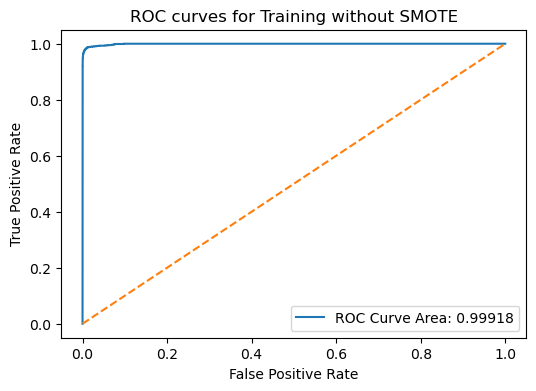

Confusion Matrix: 
[[15601    24]
 [   83   292]]

Accuracy Score: 0.99331
Error: 0.00669
ROC AUC Score: 0.99593


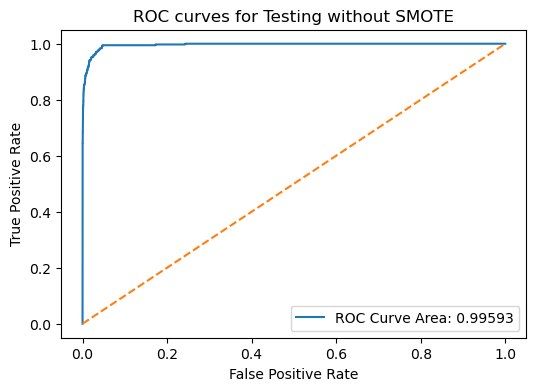

In [23]:
# The selected pipeline has already been fitted on the full training set.
y_train_predicted = xgb_model.predict(df_train_X)
y_train_prob = xgb_model.predict_proba(df_train_X)

# Preserve the assignment's separate test-imputation convention.
# The pipeline applies the training-fitted scaler.
y_test_predicted = xgb_model.predict(df_test_X_imputed)
y_test_prob = xgb_model.predict_proba(df_test_X_imputed)

stats_1 = {}

stats_1['train'] = model_summary(
    y_train,
    y_train_predicted,
    y_train_prob,
    'Training without SMOTE',
    is_xgboost=True
)

stats_1['test'] = model_summary(
    y_test,
    y_test_predicted,
    y_test_prob,
    'Testing without SMOTE',
    is_xgboost=True
)

stats_1['best_alpha'] = best_alpha

In [24]:
# ADDED: Explicitly compare CV and test misclassification errors.
cv_error_xgb = 1 - gridcv.best_score_

test_confusion = stats_1['test']['conf_matrix']
test_error_xgb = (
    test_confusion.sum() - np.trace(test_confusion)
) / test_confusion.sum()

stats_1['cv_error'] = cv_error_xgb

print(f'5-fold CV misclassification error: {cv_error_xgb:.6f}')
print(f'Test misclassification error: {test_error_xgb:.6f}')
print(f'Test minus CV error: {test_error_xgb - cv_error_xgb:+.6f}')

5-fold CV misclassification error: 0.006200
Test misclassification error: 0.006687
Test minus CV error: +0.000487


I use XGBoost with the binary logistic objective and select the L1 regularization parameter, reg_alpha, using five-fold stratified cross-validation. This implementation uses boosted decision trees; it does not fit a separate L1-penalized logistic regression model at each node.

### (f) Use SMOTE to pre-process your data

In [25]:
smote_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=69)),
    ('xgb', XGBClassifier(
        objective='binary:logistic',
        colsample_bytree=0.3,
        learning_rate=0.1,
        max_depth=5,
        random_state=69
    ))
])

smote_param_grid = {
    'xgb__reg_alpha': param_grid['reg_alpha']
}

In [26]:
gridcv = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=smote_param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=69
    ),
    scoring='accuracy',
    n_jobs=-1,
    refit=True
)


gridcv.fit(df_train_X, y_train)

best_alpha = gridcv.best_params_['xgb__reg_alpha']
smote_model = gridcv.best_estimator_
cv_error_smote = 1 - gridcv.best_score_

print('The best alpha:', best_alpha)
print('Best CV accuracy:', round(gridcv.best_score_, 5))
print('CV misclassification error:', round(cv_error_smote, 5))

The best alpha: 0.01
Best CV accuracy: 0.98893
CV misclassification error: 0.01107


Confusion Matrix: 
[[58617   383]
 [   47   953]]

Accuracy Score: 0.99283
Error: 0.00717
ROC AUC Score: 0.99844


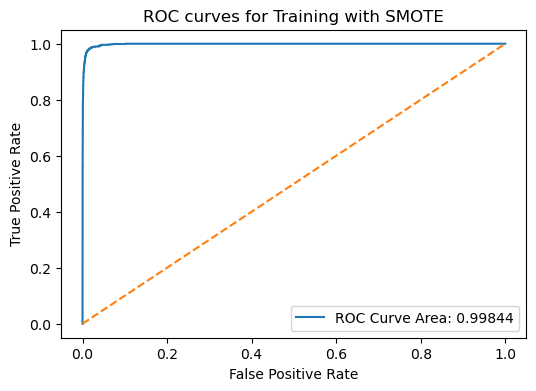

Confusion Matrix: 
[[15173   452]
 [   28   347]]

Accuracy Score: 0.97
Error: 0.03
ROC AUC Score: 0.99045


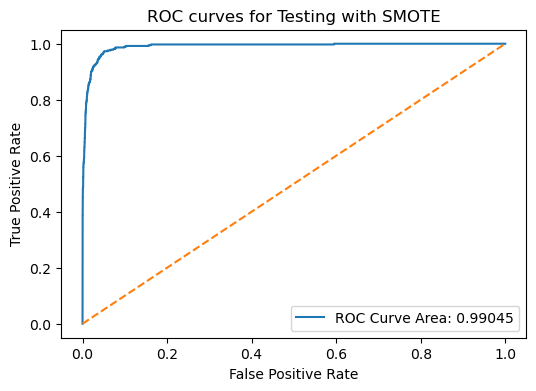

CV misclassification error: 0.01107
Test misclassification error: 0.03
Test minus CV error: 0.01893


In [27]:
y_train_predicted = smote_model.predict(df_train_X)
y_train_prob = smote_model.predict_proba(df_train_X)


y_test_predicted = smote_model.predict(df_test_X_imputed)
y_test_prob = smote_model.predict_proba(df_test_X_imputed)

stats_2 = {}

stats_2['train'] = model_summary(
    y_train,
    y_train_predicted,
    y_train_prob,
    'Training with SMOTE',
    is_xgboost=True
)

stats_2['test'] = model_summary(
    y_test,
    y_test_predicted,
    y_test_prob,
    'Testing with SMOTE',
    is_xgboost=True
)

stats_2['best_alpha'] = best_alpha

test_error_smote = 1 - accuracy_score(y_test, y_test_predicted)

print('CV misclassification error:', round(cv_error_smote, 5))
print('Test misclassification error:', round(test_error_smote, 5))
print('Test minus CV error:', round(test_error_smote - cv_error_smote, 5))

In [28]:
arr = [[stats_1['train']['error'], stats_1['train']['accuracy'], stats_1['train']['roc'], 
       stats_1['test']['error'], stats_1['test']['accuracy'], stats_1['test']['roc']], 
       [stats_2['train']['error'], stats_2['train']['accuracy'], stats_2['train']['roc'], 
       stats_2['test']['error'], stats_2['test']['accuracy'], stats_2['test']['roc']]]

df = pd.DataFrame(arr, columns = ['Train Error', 'Train Accuracy', 'Train ROC', 'Test Error', 'Test Accuracy', 'Test ROC'])
df.index = ['Without SMOTE', 'with SMOTE']
df

,Train Error,Train Accuracy,Train ROC,Test Error,Test Accuracy,Test ROC
Without SMOTE,0.00180,0.99820,0.99918,0.00669,0.99331,0.99593
with SMOTE,0.00717,0.99283,0.99844,0.03000,0.97000,0.99045


I use the same XGBoost model with SMOTE to address class imbalance. Imputation, scaling, and SMOTE are included within the cross-validation pipeline so that they are fitted only on each training fold. Validation and test observations are not oversampled.

## 2. ISLR 6.6.3

(a) **Steadily Decrease:** As we increase s value from 0 to inf, we are relaxing the constraints on $\beta$'s, hence we are going towards overfiting from underfitting. Hence training RSS would steadily decrease. 

(b) **Decrease Initially and then eventually starts increasing in a U shape.** Since we are moving from underfit model to overfit model, testing RSS will first go down and then increase for overfit models. 

(c) **Steadily Increases:** $\beta$ is almost zero in the beginning which would mean that there is almost no variance in the beginning. Hence variance will go up as we move from s = 0 to s = inf. 

(d) **Steadily Decrease:** Since the variance is increasing, the bias will decrease. This is the basics of bias-variance trade-off.

(e) **Irreducible error** is "act of god" and not in any ML model's control to change. Hence it will remain constant.

## 3. ISLR 6.6.5

### Part (a)

Let $x_{11}=x_{12}=x_1$ and $x_{21}=x_{22}=x_2$.
Since the data are centered, the intercept is zero. The ridge optimization
problem is

$$
\min_{\beta_1,\beta_2}
(y_1-x_1(\beta_1+\beta_2))^2
+(y_2-x_2(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2).
$$

### Part (b)

Define $S=x_1^2+x_2^2$ and $T=x_1y_1+x_2y_2$.

Taking partial derivatives of the ridge objective and setting them to zero gives

$$
2S(\beta_1+\beta_2)-2T+2\lambda\beta_1=0,
$$

$$
2S(\beta_1+\beta_2)-2T+2\lambda\beta_2=0.
$$

Subtracting the second equation from the first,

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Therefore, for $\lambda>0$,

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}.
$$

Substituting this equality into either equation also gives

$$
\hat{\beta}_1=\hat{\beta}_2
=\frac{T}{2S+\lambda}.
$$

### Part (c)

The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
(y_1-x_1(\beta_1+\beta_2))^2
+(y_2-x_2(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|).
$$

### Part (d)

The residual sum of squares depends only on the sum
$c=\beta_1+\beta_2$. By the triangle inequality,

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|c|.
$$

Equality holds when the coefficients have the same sign, including cases
where one coefficient is zero.

Let $c^*$ minimize

$$
(y_1-x_1c)^2+(y_2-x_2c)^2+\lambda|c|.
$$

If $c^*>0$, every pair

$$
(\hat{\beta}_1,\hat{\beta}_2)=(t,c^*-t),
\qquad 0\leq t\leq c^*
$$

is optimal. If $c^*<0$, the same expression holds with
$c^*\leq t\leq0$.

For example, $(c^*,0)$, $(0,c^*)$, and $(c^*/2,c^*/2)$
have identical fitted values and identical penalties.
Thus, when $c^*\neq0$, there are infinitely many coefficient solutions.

If $c^*=0$ and $\lambda>0$, the solution is $(0,0)$.

## 4. ISLR 8.4.5

1. **Majority Polling:** When overall probability is greater than 0.5, the classification will be true and else otherwise. Out of 10 samples, 4 samples have probability < 0.5 and 6 samples have probability >= 0.5. Since positive/True class is in majority, classification would be **red**.

2. **Average Probability:** Mean for given probabilities = 0.45 hence the classification would be **green**.

## 5. ISLR 9.7.3

In [29]:
data = pd.DataFrame({'X1': [3, 2, 4, 1, 2, 4, 4], 
                   'X2':[4, 2, 4, 4, 1, 3, 1], 
                   'Y':['red', 'red', 'red', 'red', 'blue', 'blue', 'blue']})

data['Y'].replace({'blue': 0, 'red': 1}, inplace = True)
x_train, y_train = data.drop(['Y'], axis = 1), data['Y']
model = svm.SVC(kernel = 'linear', C = 1000)
model.fit(x_train, y_train)
y_pred = model.predict(x_train)

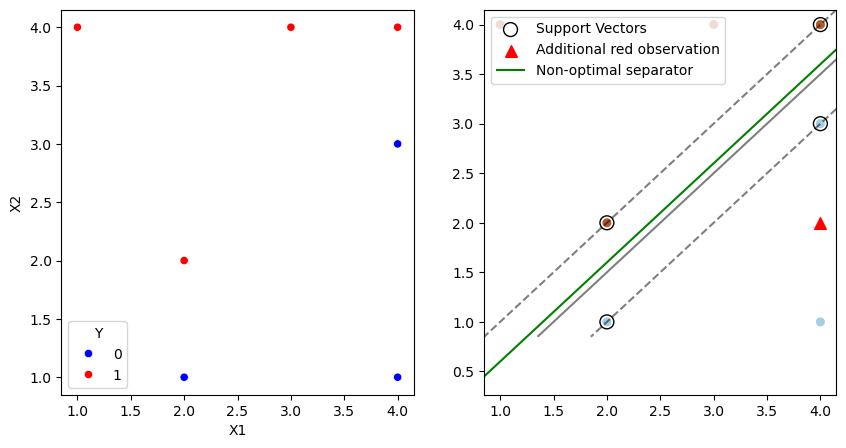

[0.99970703] [[-1.99941406  1.99941406]]


In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.scatterplot(data = data, x = "X1", y = "X2", hue = "Y", palette = ['blue', 'red'], ax = ax[0])

ax[1].scatter(data.iloc[:, 0], data.iloc[:, 1], 
              c = data.iloc[:, -1], s = 30, cmap = plt.cm.Paired)

xlim, ylim = ax[1].get_xlim(), ax[1].get_ylim()
y_axis, x_axis = np.meshgrid(np.linspace(xlim[0], xlim[1], 30), np.linspace(xlim[0], xlim[1], 30))
xy_axis = np.vstack([x_axis.ravel(), y_axis.ravel()]).T
z_axis = model.decision_function(xy_axis).reshape(x_axis.shape)


ax[1].scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s = 100,
           linewidth = 1, facecolors = 'none', edgecolors='k', label = "Support Vectors")
ax[1].scatter(
    [4.0], [2.0], color='red', marker='^',
    s=70, label='Additional red observation'
)
ax[1].plot(
    xlim,
    [value - 0.4 for value in xlim],
    color='green',
    label='Non-optimal separator'
)
ax[1].contour(x_axis, y_axis, z_axis, colors = 'k', levels = [-1, 0, 1], alpha = 0.5,
           linestyles=['--', '-', '--'], label = "Decision Boundary")
ax[1].legend(loc='upper left')

plt.show()
print(model.intercept_, model.coef_)

### (a)

The seven original observations are shown in the left-hand plot.

### (b)

The optimal separating hyperplane is the solid black line:

$$
X_2=X_1-\frac12.
$$

Equivalently,

$$
1-2X_1+2X_2=0.
$$

The closest red observations lie on $X_2=X_1$, while the closest blue
observations lie on $X_2=X_1-1$. The optimal separator lies halfway
between these parallel lines.

### (c)

Define the classification score as

$$
f(X)=1-2X_1+2X_2.
$$

Classify an observation as Red if $f(X)>0$ and Blue otherwise.
The coefficients are

$$
\boxed{\beta_0=1,\quad\beta_1=-2,\quad\beta_2=2}.
$$

### (d)

The dashed lines are the margin boundaries:

$$
X_2=X_1
\qquad\text{and}\qquad
X_2=X_1-1.
$$

The perpendicular distance from the separating hyperplane to either
boundary is

$$
M=\frac{1}{\sqrt{(-2)^2+2^2}}
=\frac{1}{2\sqrt2}.
$$

The total width between the boundaries is $2M=1/\sqrt2$.

### (e)

The support vectors are the observations on the margin boundaries:

- Red: $(2,2)$ and $(4,4)$.
- Blue: $(2,1)$ and $(4,3)$.

These observations are circled in the plot.

### (f)

The seventh observation, $(4,1)$, is blue and is not a support vector.
A sufficiently small movement that keeps it outside the margin does not
change the maximal margin hyperplane.

### (g)

The solid green line is a separating hyperplane that is not optimal:

$$
X_2=X_1-0.4.
$$

It separates all seven original observations, but its minimum distance
to the observations is smaller than that of the optimal separator.

### (h)

Add a Red observation at $(4,2)$, shown by the red triangle.
It lies halfway between two blue observations:

$$
(4,2)=\frac12(4,1)+\frac12(4,3).
$$

A linear score that assigns both blue endpoints to Blue cannot assign
their midpoint to Red. Therefore, the augmented dataset is no longer
linearly separable.